# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.
* Plotting main results, being sure of what I preparead for M. Kozak. 


# Preparation
## Loading library

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


## Going to the folder containing the database

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Database loading and quick analysis

In [3]:
# data=pd.read_csv("SiComplete-2021-08-25-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("SiComplete-2022-03-15-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
data=pd.read_csv("SiComplete-2023-02-07-BiatriSrv-v2.3-WithToleranceOnField-WithAll.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data.dtypes


##JobID                         float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
TimeStep                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_AU          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64


# Database filtering for LDA

In [4]:
data=datafull
data=data[data.Functional==IndexFunctional["LDA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data

,##JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,0.25,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,...,0.006785,0.003398,-2.567968e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.5,937.147441
1,5882467.0,20180909.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.010887,0.004497,-3.133202e+14,4.732762e+26,1.570724e+40,1.577587e+40,3.0,2.0,3087.5,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.012325,-0.076743,-1.059137e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.0,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.006391,-0.037511,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.5,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.014642,0.006659,-3.211845e+14,6.640696e+26,2.200183e+40,2.213565e+40,3.0,2.0,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2868,311136.0,20230205.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,3.000000e+09,1.162389,0.0,...,0.192894,-0.000689,2.124989e+14,7.618364e+27,1.529240e+41,1.529648e+41,1.0,0.0,5290.0,4117.988325
2869,310055.0,20230205.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,4.000000e+09,0.376991,0.0,...,0.407612,-0.001255,1.494113e+15,1.671259e+28,3.354673e+41,3.355627e+41,1.0,0.0,5290.0,4117.988325
2870,300913.0,20221211.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,3.000000e+09,0.376991,0.0,...,0.192894,-0.000865,4.186992e+14,7.618364e+27,1.529240e+41,1.529648e+41,1.0,0.0,5290.0,4117.988325
2871,310622.0,20230202.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,2.000000e+09,0.376991,0.0,...,0.047799,-0.000002,-1.466638e+14,1.916942e+27,3.844124e+40,3.848920e+40,1.0,0.0,5290.0,4117.988325


In [5]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==0]
data

,##JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,0.25,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,...,0.006785,0.003398,-2.567968e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.5,937.147441
1,5882467.0,20180909.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.010887,0.004497,-3.133202e+14,4.732762e+26,1.570724e+40,1.577587e+40,3.0,2.0,3087.5,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.012325,-0.076743,-1.059137e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.0,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.006391,-0.037511,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.5,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.014642,0.006659,-3.211845e+14,6.640696e+26,2.200183e+40,2.213565e+40,3.0,2.0,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2868,311136.0,20230205.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,3.000000e+09,1.162389,0.0,...,0.192894,-0.000689,2.124989e+14,7.618364e+27,1.529240e+41,1.529648e+41,1.0,0.0,5290.0,4117.988325
2869,310055.0,20230205.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,4.000000e+09,0.376991,0.0,...,0.407612,-0.001255,1.494113e+15,1.671259e+28,3.354673e+41,3.355627e+41,1.0,0.0,5290.0,4117.988325
2870,300913.0,20221211.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,3.000000e+09,0.376991,0.0,...,0.192894,-0.000865,4.186992e+14,7.618364e+27,1.529240e+41,1.529648e+41,1.0,0.0,5290.0,4117.988325
2871,310622.0,20230202.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,2.000000e+09,0.376991,0.0,...,0.047799,-0.000002,-1.466638e+14,1.916942e+27,3.844124e+40,3.848920e+40,1.0,0.0,5290.0,4117.988325


In [6]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [7]:
datafull

,##JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
163,5109637.0,20180601.0,24.0,0.434637,0.25,2.000000e-07,2.000000e-14,1.000000e+08,0.0,0.0,...,8.262708e-04,0.000004,-2.583857e+11,3.957254e+25,1.973568e+39,1.978627e+39,3.0,2.0,3812.5,854.407455
1468,8715191.0,20190625.0,24.0,0.434637,0.25,2.000000e-07,2.000000e-14,5.000000e+08,0.0,0.0,...,1.952543e-02,-0.000109,-7.046549e+12,9.323506e+26,4.661432e+40,4.661753e+40,3.0,2.0,3125.0,854.407455
1523,8918119.0,20190708.0,24.0,0.434637,0.25,2.000000e-07,2.000000e-14,7.500000e+08,0.0,0.0,...,4.079272e-02,-0.000297,-9.950841e+12,1.940461e+27,9.701183e+40,9.702303e+40,3.0,2.0,3125.0,854.407455
312,5027620.0,20180524.0,24.0,0.434637,0.25,2.000000e-07,2.000000e-14,1.000000e+09,0.0,0.0,...,6.555565e-02,0.000637,5.249025e+12,3.099319e+27,1.549393e+41,1.549659e+41,3.0,2.0,2975.0,854.407455
1413,8918121.0,20190709.0,24.0,0.434637,0.25,2.000000e-07,2.000000e-14,1.500000e+09,0.0,0.0,...,1.123667e-01,-0.001849,-1.315329e+13,5.230000e+27,2.614998e+41,2.615000e+41,3.0,2.0,3125.0,854.407455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1403,10050046.0,20191101.0,24.0,0.434637,0.25,4.100000e-06,2.000000e-14,5.000000e+08,0.0,0.0,...,3.690789e-07,0.000226,4.772547e+13,3.844612e+27,2.465914e+35,1.922306e+41,3.0,2.0,3750.0,1392.217365
1738,17608855.0,20200127.0,24.0,0.434637,0.25,6.400000e-06,6.000000e-14,5.000000e+08,0.0,0.0,...,2.562692e-06,0.000335,9.126526e+13,5.590327e+24,7.342516e+34,9.317212e+37,3.0,2.0,7750.0,3363.042231
1735,17638129.0,20200127.0,24.0,0.434637,0.25,6.400000e-06,6.000000e-14,7.500000e+08,0.0,0.0,...,2.733345e-05,0.000839,7.494762e+13,1.337371e+25,1.286704e+37,2.228952e+38,3.0,2.0,7625.0,3363.042231
1711,17608858.0,20200127.0,24.0,0.434637,0.25,6.400000e-06,6.000000e-14,1.000000e+09,0.0,0.0,...,4.830202e-04,0.001603,-5.717359e+12,3.822728e+25,2.664830e+38,6.371213e+38,3.0,2.0,7500.0,3363.042231


## Convergence of $J(t)$ in k-grid

In [8]:
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
# datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9] #Bicolor runs
# datatmp=datatmp[np.fabs(datatmp.lambda2-1.367968e-6/2.)<1e-9]
datatmp=datatmp[np.fabs(datatmp.lambda1-2.65625e-6)<1e-9] #Kozak 2000 nm
datatmp=datatmp[datatmp.Efield2==0]
datatmp=datatmp[datatmp.Efield1==3E9]
datatmp=datatmp[datatmp.CEP1==0]
datatmp=datatmp[datatmp.STH==1]
datatmp=datatmp[np.fabs(datatmp.tau1-13.94e-15)<1E-15]
datatmp=datatmp[datatmp.PolarizationAngle==0]
data2 = datatmp

# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

In [9]:
datatmp

,##JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2303,441931.0,20210429.0,24.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.0,0.0,...,0.0,0.058094,-1.110208e+15,1.973202e+27,1.416821e+41,1.414989e+41,1.0,0.0,3266.25,1153.010893
2332,460293.0,20210531.0,24.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.0,0.0,...,0.0,0.058094,-1.110208e+15,1.973202e+27,1.416821e+41,1.414989e+41,1.0,0.0,3266.25,1153.010893
2744,499932.0,20210804.0,32.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.0,0.0,...,0.0,0.057720,-7.741582e+14,1.975252e+27,1.417607e+41,1.416459e+41,1.0,0.0,2750.00,1153.010893
2653,498934.0,20210803.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.0,0.0,...,0.0,0.057432,7.007967e+14,1.974000e+27,1.415733e+41,1.415561e+41,1.0,0.0,1375.00,1153.010893
2651,513084.0,20210902.0,48.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.0,0.0,...,0.0,0.057434,-1.091467e+15,1.974034e+27,1.417301e+41,1.415585e+41,1.0,0.0,3266.25,1153.010893


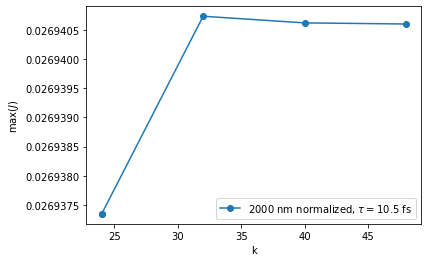

In [10]:
plt.figure()
plt.plot(data2.kgrid, data2.MaxJx, "-o", label=r"2000 nm normalized, $\tau=$10.5 fs")
plt.xlabel(r"k")
plt.ylabel(r"max$(J)$")
plt.legend()
plt.show()

## Effect of k-grid on HHG spectrum

In [11]:
"""spectrum48=np.loadtxt(path48, delimiter="\t")
spectrum40=np.loadtxt(path40, delimiter="\t")

spectrum32=np.loadtxt(path32, delimiter="\t")
spectrum24=np.loadtxt(path24, delimiter="\t")
"""

'spectrum48=np.loadtxt(path48, delimiter="\t")\nspectrum40=np.loadtxt(path40, delimiter="\t")\n\nspectrum32=np.loadtxt(path32, delimiter="\t")\nspectrum24=np.loadtxt(path24, delimiter="\t")\n'

In [12]:
"""plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel('Spectrum (arb. u.)')
plt.semilogy(spectrum48[:,0], spectrum48[:,1], '-',  label=r"$k=48^{3}$")
plt.semilogy(spectrum40[:,0], spectrum40[:,1], '--', label=r"$k=40^{3}$")

# plt.semilogy(spectrum32[:,0], spectrum32[:,1], '--', label=r"$k=32^{3}$")
# plt.semilogy(spectrum24[:,0], spectrum24[:,1], '.',  label=r"$k=24^{3}$")
plt.xlim([0,80])
plt.legend(loc="best")
plt.savefig("Convergence-LDA-lambda2656e-9-tau13.945e-15-field3E9-CEP0.0-theta0.25-SinSquared-SinPower2.eps")
plt.show()
"""

'plt.figure()\nplt.xlabel("Energy (eV)")\nplt.ylabel(\'Spectrum (arb. u.)\')\nplt.semilogy(spectrum48[:,0], spectrum48[:,1], \'-\',  label=r"$k=48^{3}$")\nplt.semilogy(spectrum40[:,0], spectrum40[:,1], \'--\', label=r"$k=40^{3}$")\n\n# plt.semilogy(spectrum32[:,0], spectrum32[:,1], \'--\', label=r"$k=32^{3}$")\n# plt.semilogy(spectrum24[:,0], spectrum24[:,1], \'.\',  label=r"$k=24^{3}$")\nplt.xlim([0,80])\nplt.legend(loc="best")\nplt.savefig("Convergence-LDA-lambda2656e-9-tau13.945e-15-field3E9-CEP0.0-theta0.25-SinSquared-SinPower2.eps")\nplt.show()\n'

In [13]:
"""plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel('Spectrum (arb. u.)')
plt.semilogy(spectrum48[:,0], spectrum48[:,1], '-',  label=r"$k=48^{3}$")
plt.semilogy(spectrum40[:,0], spectrum40[:,1], '--', label=r"$k=40^{3}$")

# plt.semilogy(spectrum32[:,0], spectrum32[:,1], '--', label=r"$k=32^{3}$")
# plt.semilogy(spectrum24[:,0], spectrum24[:,1], '.',  label=r"$k=24^{3}$")
plt.xlim([0,15])
plt.legend(loc="best")
plt.savefig("Convergence-LDA-lambda2656e-9-tau13.945e-15-field3E9-CEP0.0-theta0.25-SinSquared-SinPower2-Zoom.eps")
plt.show()
"""

'plt.figure()\nplt.xlabel("Energy (eV)")\nplt.ylabel(\'Spectrum (arb. u.)\')\nplt.semilogy(spectrum48[:,0], spectrum48[:,1], \'-\',  label=r"$k=48^{3}$")\nplt.semilogy(spectrum40[:,0], spectrum40[:,1], \'--\', label=r"$k=40^{3}$")\n\n# plt.semilogy(spectrum32[:,0], spectrum32[:,1], \'--\', label=r"$k=32^{3}$")\n# plt.semilogy(spectrum24[:,0], spectrum24[:,1], \'.\',  label=r"$k=24^{3}$")\nplt.xlim([0,15])\nplt.legend(loc="best")\nplt.savefig("Convergence-LDA-lambda2656e-9-tau13.945e-15-field3E9-CEP0.0-theta0.25-SinSquared-SinPower2-Zoom.eps")\nplt.show()\n'

Conclusion: using LDA, HHG convergence is good for $k=40^3$

## Effect of field on HHG spectrum
Warning: selection of the runs is manual here. Automatic selection would require to store path in a database associated with ID of the runs. 

In [14]:
path1_4E9="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.75tau/HHG-Spectrum.csv"
path3E9="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field3E9-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/HHG-Spectrum.csv"
path9E9="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field9E9-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/HHG-Spectrum.csv"

In [15]:
spectrum1_4E9=np.loadtxt(path1_4E9, delimiter="\t")
spectrum3E9=np.loadtxt(path3E9, delimiter="\t")
spectrum9E9=np.loadtxt(path9E9, delimiter="\t")

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:7: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  import sys
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


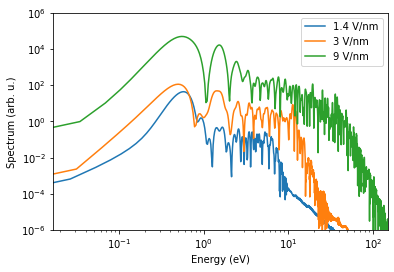

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [16]:
plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel('Spectrum (arb. u.)')
plt.loglog(spectrum1_4E9[:,0], spectrum1_4E9[:,1], label="1.4 V/nm")
plt.loglog(spectrum3E9[:,0], spectrum3E9[:,1], label="3 V/nm")
plt.loglog(spectrum9E9[:,0], spectrum9E9[:,1], label="9 V/nm")
plt.xlim([0,150])
plt.ylim([1E-6,1E6])
plt.legend(loc="best")
plt.savefig("HHGspectrumWithField-wavelength2656nm-EffectOfField-Log.eps")
plt.show()
%pwd

One recovers well the piedestal formation upon increase of the light intensity.

## Effect of orientation on HHG spectrum (LDA)

### 10 fs pulses, $\sin^2$

In [17]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2656e-9
from scipy.constants import h, c, hbar, e

In [18]:
path0="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field"+Efield+"-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.75tau/HHG-Spectrum.csv"
path45="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field"+Efield+"-CEP0.0-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.75tau/HHG-Spectrum.csv"

In [19]:
print(path0)
print(path45)

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.75tau/HHG-Spectrum.csv
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.75tau/HHG-Spectrum.csv


In [20]:
spectrum0=np.loadtxt(path0, delimiter="\t")
spectrum45=np.loadtxt(path45, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


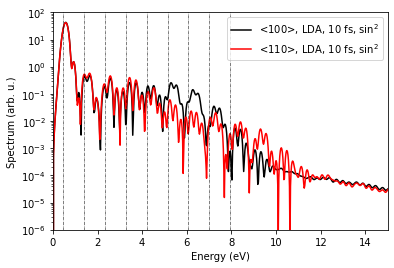

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [21]:
plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(spectrum0[:,0], spectrum0[:,1], "k-", label=r"<100>, LDA, 10 fs, $\sin^2$")
plt.semilogy(spectrum45[:,0], spectrum45[:,1], "r-", label=r"<110>, LDA, 10 fs, $\sin^2$")
plt.xlim([0,15])
plt.ylim([1E-6,1E2])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-LDA-100vs110-"+str(round(float(Efield)/1E9,1))+"Vnm.eps")
plt.show()
%pwd

Observations
* For 1.4 V/nm, LDA functional seems to be at the opposite of experimental results provided by M. Kozak. 
* At 3 V/nm, LDA functional seem to be working, kind of. We find the right domination between angles as function of order. 
* At 9 V/nm, it seems calculation at 45 deg was not finished. 

How to improve? 
* It can be originating from misidentification of crystal orientation. 
* I am also attempting other functionals, such as TB09. 

# Database filtering for TB09

## Convergence of $J(t)$ in k-grid

## Effect of k-grid on HHG spectrum

## Effect of orientation on HHG spectrum

In [22]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2237e-9
decoherence="1.75"
path0="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field"+Efield+"-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path45="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field"+Efield+"-CEP0.0-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [23]:
print(path0)
print(path45)

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.75tau/HHG-Spectrum.csv
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.75tau/HHG-Spectrum.csv


In [24]:
spectrum0=np.loadtxt(path0, delimiter="\t")
spectrum45=np.loadtxt(path45, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


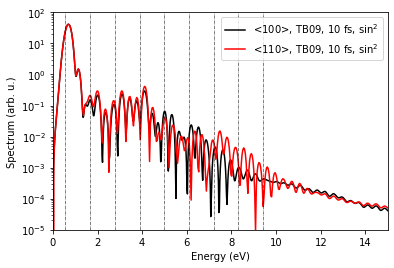

In [25]:
plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(spectrum0[:,0], spectrum0[:,1], "k-", label=r"<100>, TB09, 10 fs, $\sin^2$")
plt.semilogy(spectrum45[:,0], spectrum45[:,1], "r-", label=r"<110>, TB09, 10 fs, $\sin^2$")
plt.xlim([0,15])
plt.ylim([1E-5,1E2])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-TB09-100vs110-"+str(float(Efield)/1E9)+"Vnm.eps")
plt.show()

# Comparison LDA vs TB09 spectra

## Angle 0° (100)

In [26]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength_LDA=2656E-9
wavelength_TB09=2237e-9
decoherence="1.5"
path_TB09="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field"+Efield+"-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_LDA ="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field"+Efield+"-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [27]:
print(path_LDA)
print(path_TB09)

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.5tau/HHG-Spectrum.csv
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.5tau/HHG-Spectrum.csv


In [28]:
spectrum_LDA=np.loadtxt(path_LDA, delimiter="\t")
spectrumTB09=np.loadtxt(path_TB09, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


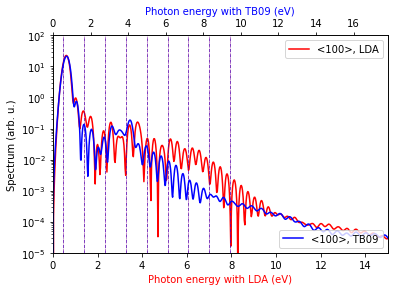

In [29]:
energy_max=15 #eV

plt.figure()
ax1=plt.subplot(111)
plt.xlabel("Photon energy with LDA (eV)", color="red")
plt.ylabel("Spectrum (arb. u.)")
ax1.semilogy(spectrum_LDA[:,0], spectrum_LDA[:,1], "r-", label="<100>, LDA")
plt.xlim([0,energy_max])
ax1.legend()
    
ax12=ax1.twiny() #lets use a second X axis
plt.xlabel("Photon energy with TB09 (eV)", color="blue")
ax12.semilogy(spectrumTB09[:,0], spectrumTB09[:,1], "b-", label="<100>, TB09")
plt.xlim([0,energy_max*3.04/2.56])
plt.ylim([1E-5,1E2])
ax12.legend(loc=4)

for NumPhot in [1,3,5,7,9,11,13,15,17]:
    ax1.axvline( x=NumPhot*h*c/e/wavelength_LDA,  color='r', linewidth=0.5, linestyle="-.")
    ax12.axvline(x=NumPhot*h*c/e/wavelength_TB09, color='b', linewidth=0.5, linestyle="-.")
    # TB09 is based on Hartree-Fock exchange. 
# Maybe Rubio PRL2002 functional for next time? 
# Then HSE? 
plt.savefig("Si-k40-100-1.4Vnm-LDAvsTB09-Decoherence"+decoherence+"tau.eps")
plt.show()

## Angle 45° (110)

In [30]:
decoherence="1.5"
path_TB09="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field"+Efield+"-CEP0.0-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_LDA="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field"+Efield+"-CEP0.0-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [31]:
print(path_LDA)
print(path_TB09)

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.5tau/HHG-Spectrum.csv
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence1.5tau/HHG-Spectrum.csv


In [32]:
spectrum_LDA=np.loadtxt(path_LDA, delimiter="\t")
spectrumTB09=np.loadtxt(path_TB09, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


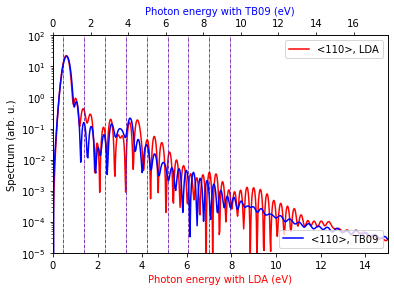

In [33]:
energy_max=15 #eV

plt.figure()
ax1=plt.subplot(111)
plt.xlabel("Photon energy with LDA (eV)", color="red")
plt.ylabel("Spectrum (arb. u.)")
ax1.semilogy(spectrum_LDA[:,0], spectrum_LDA[:,1], "r-", label="<110>, LDA")
plt.xlim([0,energy_max])
ax1.legend()
    
ax12=ax1.twiny() #lets use a second X axis
ax12.semilogy(spectrumTB09[:,0], spectrumTB09[:,1], "b-", label="<110>, TB09")
plt.xlabel("Photon energy with TB09 (eV)", color="blue")
plt.xlim([0,energy_max*3.04/2.56])
plt.ylim([1E-5,1E2])
ax12.legend(loc=4)

for NumPhot in [1,3,5,7,9,11,13,15,17]:
    ax1.axvline( x=NumPhot*h*c/e/wavelength_LDA,  color='r', linewidth=0.5, linestyle="-.")
    ax12.axvline(x=NumPhot*h*c/e/wavelength_TB09, color='b', linewidth=0.5, linestyle="-.")
    # TB09 is based on Hartree-Fock exchange. 
# Maybe Rubio PRL2002 functional for next time? 
# Then HSE? 
plt.savefig("Si-k40-110-1.4Vnm-LDAvsTB09-Decoherence"+decoherence+"tau.eps")
plt.show()

The ordering of spectral intensities between 7th, 9th, and 11th harmonic is well respected by both functionals. 

Remains to be done: 
* We shall make similar comparison for orientation 45°. 

# Effect of pulse envelope

## sin² vs $\sin^4$ (LDA)

We have changed Sin² into Sin^4. Let's see the effect of HHG spectrum. 

In [34]:
from scipy.constants import h, c, e

In [35]:
Efield="1.4E9" #3E9
CEP="0.0" #0.5
decoherence="1.5"
Path_SinFourth ="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field"+Efield+"-CEP"+CEP+"-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
Path_SinSquared="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field"+Efield+"-CEP"+CEP+"-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [36]:
print(Path_SinFourth)
print("/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.5-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv")

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.5tau/HHG-Spectrum.csv
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.5-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.5tau/HHG-Spectrum.csv


In [37]:
SinSquared=np.loadtxt(Path_SinSquared)
SinFourth=np.loadtxt(Path_SinFourth)

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


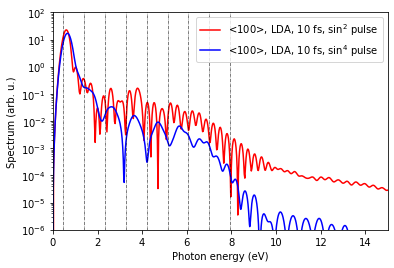

In [38]:
energy_max=15 #eV

plt.figure()
ax1=plt.subplot(111)
plt.xlabel("Photon energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
ax1.semilogy(SinSquared[:,0], SinSquared[:,1], "r-", label=r"<100>, LDA, 10 fs, sin$^2$ pulse")
ax1.semilogy(SinFourth[:,0], SinFourth[:,1], "b-",   label=r"<100>, LDA, 10 fs, sin$^4$ pulse")
plt.xlim([0,energy_max])
plt.ylim([1E-6,1E2])
ax1.legend()

for NumPhot in [1,3,5,7,9,11,13,15,17]:
    ax1.axvline( x=NumPhot*h*c/e/wavelength_LDA,  color='k', linewidth=0.5, linestyle="-.")
#    ax12.axvline(x=NumPhot*h*c/e/wavelength_TB09, color='b', linewidth=0.5, linestyle="-.")
    # TB09 is based on Hartree-Fock exchange. 
# Maybe Rubio PRL2002 functional for next time? 
# Then HSE? 
plt.savefig("Si-k40-100-"+Efield+"Vm-CEP"+CEP+"LDA-Sin2vsSin4-Decoherence"+decoherence+"tau.eps")
plt.show()

### <100> vs <110> (LDA, $\sin^4$)

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


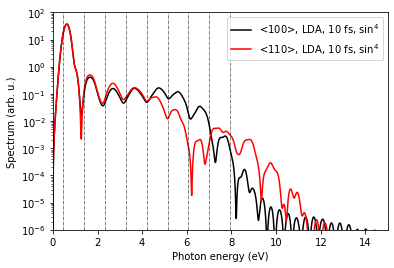

In [39]:
Efield="1.4E9" #3E9
CEP="0.0" #0.5
decoherence="1.75"
Path_SinFourth_100="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field"+Efield+"-CEP"+CEP+"-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
Path_SinFourth_110="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
SinFourth_100=np.loadtxt(Path_SinFourth_100)
SinFourth_110=np.loadtxt(Path_SinFourth_110)
energy_max=15 #eV

plt.figure()
ax1=plt.subplot(111)
plt.xlabel("Photon energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
ax1.semilogy(SinFourth_100[:,0], SinFourth_100[:,1], "k-", label=r"<100>, LDA, 10 fs, sin$^4$")
ax1.semilogy(SinFourth_110[:,0], SinFourth_110[:,1], "r-", label=r"<110>, LDA, 10 fs, sin$^4$")
plt.xlim([0,energy_max])
plt.ylim([1E-6,1E2])
ax1.legend()

for NumPhot in [1,3,5,7,9,11,13,15,17]:
    ax1.axvline( x=NumPhot*h*c/e/wavelength_LDA,  color='k', linewidth=0.5, linestyle="-.")
#    ax12.axvline(x=NumPhot*h*c/e/wavelength_TB09, color='b', linewidth=0.5, linestyle="-.")
    # TB09 is based on Hartree-Fock exchange. 
# Maybe Rubio PRL2002 functional for next time? 
# Then HSE? 
plt.savefig("Si-k40-100vs110-"+Efield+"Vm-CEP"+CEP+"LDA-Sin4-10fs-Decoherence"+decoherence+"tau.eps")
plt.show()

## $\sin^2$ vs $\sin^4$ (TB09)

In [40]:
Efield="1.4E9" #3E9
CEP="0.0" #0.5
decoherence="1.75"
path_SinFourthTB09 ="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_SinSquaredTB09="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [41]:
SinSquared=np.loadtxt(path_SinSquaredTB09)
SinFourth=np.loadtxt(path_SinFourthTB09)

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


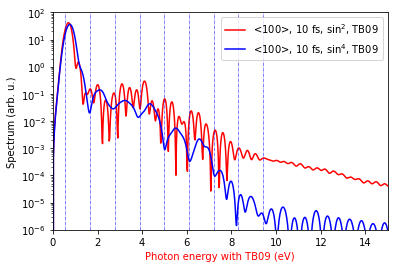

In [42]:
energy_max=15 #eV

plt.figure()
ax1=plt.subplot(111)
plt.xlabel("Photon energy with TB09 (eV)", color="red")
plt.ylabel("Spectrum (arb. u.)")
ax1.semilogy(SinSquared[:,0], SinSquared[:,1], "r-", label=r"<100>, 10 fs, $\sin^2$, TB09")
ax1.semilogy(SinFourth[:,0], SinFourth[:,1], "b-",   label=r"<100>, 10 fs, $\sin^4$, TB09")
plt.xlim([0,energy_max])
plt.ylim([1E-6,1E2])
ax1.legend()

for NumPhot in [1,3,5,7,9,11,13,15,17]:
#    ax1.axvline( x=NumPhot*h*c/e/wavelength_LDA,  color='k', linewidth=0.5, linestyle="-.")
    ax1.axvline(x=NumPhot*h*c/e/wavelength_TB09, color='b', linewidth=0.5, linestyle="-.")
    # TB09 is based on Hartree-Fock exchange. 
# Maybe Rubio PRL2002 functional for next time? 
# Then HSE? 
plt.savefig("Si-k40-100-"+Efield+"Vm-CEP"+CEP+"TB09-Sin2vsSin4-Decoherence"+decoherence+"tau.eps")
plt.show()

## Effect of LDA/TB09 (sin4)

### <100>

In [43]:
Efield="1.4E9" #3E9
CEP="0.0" #0.5
decoherence="1.75"
path_SinFourth_LDA= "/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field"+Efield+"-CEP"+CEP+"-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_SinFourth_TB09="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [44]:
print(path_SinFourth_LDA)
print(path_SinFourth_TB09)

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.75tau/HHG-Spectrum.csv
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.75tau/HHG-Spectrum.csv


In [45]:
SinFourthLDA=np.loadtxt(path_SinFourth_LDA)
SinFourthTB09=np.loadtxt(path_SinFourth_TB09)

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


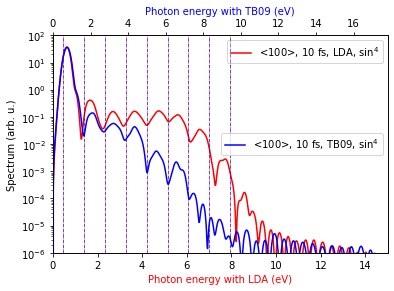

In [46]:
energy_max=15 #eV

plt.figure()
ax1=plt.subplot(111)
plt.xlabel("Photon energy with LDA (eV)", color="red")
plt.ylabel("Spectrum (arb. u.)")
ax1.semilogy(SinFourthLDA[:,0], SinFourthLDA[:,1], "r-", label=r"<100>, 10 fs, LDA, sin$^4$")
plt.xlim([0,energy_max])
ax1.legend()
    
ax12=ax1.twiny() #lets use a second X axis
plt.xlabel("Photon energy with TB09 (eV)", color="blue")
ax12.semilogy(SinFourthTB09[:,0], SinFourthTB09[:,1], "b-", label=r"<100>, 10 fs, TB09, sin$^4$")
plt.xlim([0,energy_max*3.04/2.56])
plt.ylim([1E-6,1E2])
ax12.legend(loc=5)

for NumPhot in [1,3,5,7,9,11,13,15,17]:
    ax1.axvline( x=NumPhot*h*c/e/wavelength_LDA,  color='r', linewidth=0.5, linestyle="-.")
    ax12.axvline(x=NumPhot*h*c/e/wavelength_TB09, color='b', linewidth=0.5, linestyle="-.")
    # TB09 is based on Hartree-Fock exchange. 
# Maybe Rubio PRL2002 functional for next time? 
# Then HSE? 
plt.savefig("Si-k40-100-1.4Vnm-LDAvsTB09-SinFourth-Decoherence"+decoherence+"tau.eps")
plt.show()

### <110>

In [47]:
del path_SinFourth_LDA, path_SinFourth_TB09
Efield="1.4E9" #3E9
CEP="0.0" #0.5
decoherence="1.75"
path_SinFourth_LDA= "/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_SinFourth_TB09="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
print(path_SinFourth_LDA)
print(path_SinFourth_TB09)

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.75tau/HHG-Spectrum.csv
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.75tau/HHG-Spectrum.csv


In [48]:
# del SinFourthLDA, SinFourthTB09
SinFourthLDA=np.loadtxt(path_SinFourth_LDA)
SinFourthTB09=np.loadtxt(path_SinFourth_TB09)

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


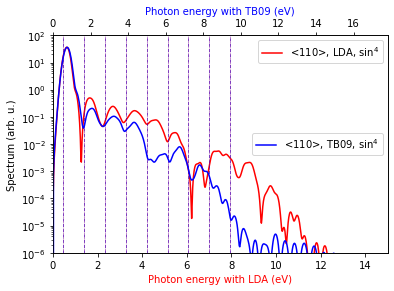

In [49]:
energy_max=15 #eV

plt.figure()
ax1=plt.subplot(111)
plt.xlabel("Photon energy with LDA (eV)", color="red")
plt.ylabel("Spectrum (arb. u.)")
ax1.semilogy(SinFourthLDA[:,0], SinFourthLDA[:,1], "r-", label=r"<110>, LDA, sin$^4$")
plt.xlim([0,energy_max])
ax1.legend()
    
ax12=ax1.twiny() #lets use a second X axis
plt.xlabel("Photon energy with TB09 (eV)", color="blue")
ax12.semilogy(SinFourthTB09[:,0], SinFourthTB09[:,1], "b-", label=r"<110>, TB09, sin$^4$")
plt.xlim([0,energy_max*3.04/2.56])
plt.ylim([1E-6,1E2])
ax12.legend(loc=5)

for NumPhot in [1,3,5,7,9,11,13,15,17]:
    ax1.axvline( x=NumPhot*h*c/e/wavelength_LDA,  color='r', linewidth=0.5, linestyle="-.")
    ax12.axvline(x=NumPhot*h*c/e/wavelength_TB09, color='b', linewidth=0.5, linestyle="-.")
    # TB09 is based on Hartree-Fock exchange. 
# Maybe Rubio PRL2002 functional for next time? 
# Then HSE? 
plt.savefig("Si-k40-110-1.4Vnm-LDAvsTB09-SinFourth-Decoherence"+decoherence+"tau.eps")
plt.show()

## Effect of CEP (LDA)

In [50]:
# del path_SinFourthCEPhalf; del path_SinFourthCEPzero
path_SinFourthCEPhalf="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.5-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
path_SinFourthCEPzero="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.75tau/HHG-Spectrum.csv"

In [51]:
SinFourthCEPhalf=np.loadtxt(path_SinFourthCEPhalf)
SinFourthCEPzero=np.loadtxt(path_SinFourthCEPzero)
print(SinFourthCEPhalf)

[[0.00000000e+00 0.00000000e+00]
 [1.30844250e-02 3.04563602e-05]
 [2.61688499e-02 1.32266080e-04]
 ...
 [3.41922193e+02 2.08837205e-11]
 [3.41935277e+02 2.05194413e-11]
 [3.41948362e+02 2.03943435e-11]]


  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


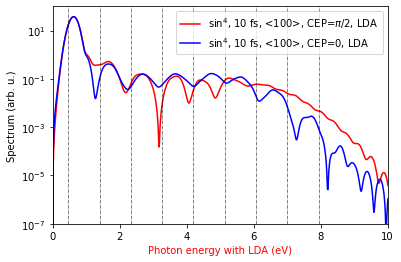

In [52]:
energy_max=10 #eV
Efield="1.4E9"
plt.figure()
ax1=plt.subplot(111)
plt.xlabel("Photon energy with LDA (eV)", color="red")
plt.ylabel("Spectrum (arb. u.)")
ax1.semilogy(SinFourthCEPhalf[:,0], SinFourthCEPhalf[:,1], "r-", label=r"sin$^4$, 10 fs, <100>, CEP=$\pi/2$, LDA")
ax1.semilogy(SinFourthCEPzero[:,0], SinFourthCEPzero[:,1], "b-", label=r"sin$^4$, 10 fs, <100>, CEP=$0$, LDA")
plt.xlim([0,energy_max])
plt.ylim([1E-7,1E2])
ax1.legend()

for NumPhot in [1,3,5,7,9,11,13,15,17]:
    ax1.axvline( x=NumPhot*h*c/e/wavelength_LDA,  color='k', linewidth=0.5, linestyle="-.")
#    ax12.axvline(x=NumPhot*h*c/e/wavelength_TB09, color='b', linewidth=0.5, linestyle="-.")
    # TB09 is based on Hartree-Fock exchange. 
# Maybe Rubio PRL2002 functional for next time? 
# Then HSE? 
plt.savefig("Si-k40-100-"+Efield+"Vm-SinFourth-CEP0vs0.5.eps")
plt.show()

We can clearly see that maxima are moving while CEP is changing. Therefore, even if using a cos instead of a sin, we don't solve the problem found by Martin that ultrafast current would increase so quick. He will have to filter by himself anyhow. 

## Effect of orientation (sin4, TB09)

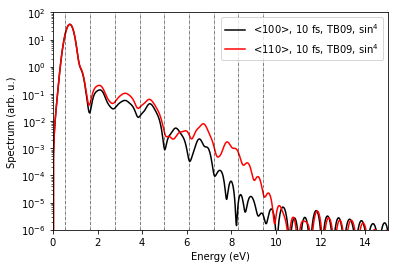

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [53]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2237e-9
path0="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
path45="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.75tau/HHG-Spectrum.csv"
spectrum0=np.loadtxt(path0, delimiter="\t")
spectrum45=np.loadtxt(path45, delimiter="\t")
plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(spectrum0[:,0], spectrum0[:,1], "k-", label=r"<100>, 10 fs, TB09, $\sin^{4}$")
plt.semilogy(spectrum45[:,0], spectrum45[:,1], "r-", label=r"<110>, 10 fs, TB09, $\sin^{4}$")
plt.xlim([0,15])
plt.ylim([1E-6,1E2])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-TB09-SinFourth-100vs110-"+str(round(float(Efield)/1E9,1))+"Vnm.png")
plt.show()
%pwd

## Effect of pulse duration ($sin^4$)

### LDA, 8 atoms vs bulk, 100

In [54]:
path_33fs_100_bulk="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau33.203125e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP-0.45-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
path_33fs_100_8atoms="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D.8atoms/Si-1x1x1-k-24x24x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau33.203125e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP-0.45-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
path_66fs_100_8atoms="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D.8atoms/Si-1x1x1-k-24x24x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau66.40625e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP-0.45-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"

In [55]:
data_33fs_100_bulk=np.loadtxt(path_33fs_100_bulk, delimiter="\t")
data_33fs_100_8atoms =np.loadtxt(path_33fs_100_8atoms,  delimiter="\t")
data_66fs_100_8atoms =np.loadtxt(path_66fs_100_8atoms,  delimiter="\t")

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:10: MatplotlibDeprecationWarning: Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  # Remove the CWD from sys.path while we load stuff.


Si-k40bulkVS8atomsK24-LDA-100-SinFourth-25fs-1.4Vnm.eps


  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


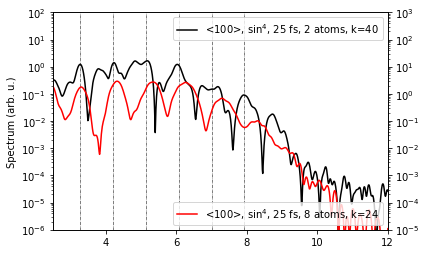

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [56]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2656e-9
energymin=2.5
energymax=12 #eV

plt.figure()
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")

ax1=plt.subplot(111)

plt.ylabel("Spectrum (arb. u.)")
ax1.semilogy(data_33fs_100_bulk[:,0], data_33fs_100_bulk[:,1],      "k-", label=r"<100>, $\sin^{4}$, 25 fs, 2 atoms, k=40")

ax12=ax1.twinx() #lets use a second X axis
ax12.semilogy(data_33fs_100_8atoms[:,0], data_33fs_100_8atoms[:,1], "r-", label=r"<100>, $\sin^{4}$, 25 fs, 8 atoms, k=24")
# ax12.semilogy(data_66fs_100_8atoms[:,0], data_66fs_100_8atoms[:,1], "b--", label=r"<100>, $\sin^{4}$, 50 fs, 8 atoms, k=24")

ax1.set_xlim([energymin,energymax])
ax12.set_xlim([energymin,energymax])

ax1.set_ylim([1E-6,1E2])
ax12.set_ylim([1E-5,1E3])


plt.xlabel("Energy (eV)")
# plt.semilogy(data_66fs_100_8atoms[:,0], data_66fs_100_8atoms[:,1], "-", label=r"<100>, $\sin^{4}$, 50 fs, 8 atoms, k=24")
ax1.legend(loc=1)
ax12.legend(loc=4)

filename="Si-k40bulkVS8atomsK24-LDA-100-SinFourth-25fs-"+str(round(float(Efield)/1E9,1))+"Vnm.eps"

print(filename)
plt.savefig(filename)
plt.show()
%pwd

### TB09, 100

In [57]:
decoherence="1.75"
path_short_pulse_100="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_long_pulse_100 ="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [58]:
short_pulse_100=np.loadtxt(path_short_pulse_100, delimiter="\t")
short_long_100 =np.loadtxt(path_long_pulse_100,  delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


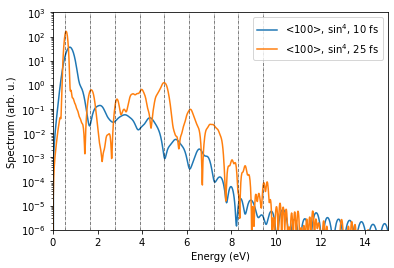

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [59]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2237e-9
plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(short_pulse_100[:,0], short_pulse_100[:,1], "-", label=r"<100>, $\sin^{4}$, 10 fs")
plt.semilogy(short_long_100[:,0], short_long_100[:,1], "-", label=r"<100>, $\sin^{4}$, 25 fs")
plt.xlim([0,15])
plt.ylim([1E-6,1E3])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-TB09-100-SinFourth-10fsVS25fs-"+str(round(float(Efield)/1E9,1))+"Vnm-Decoherence"+decoherence+"tau.eps")
plt.show()
%pwd

### TB09, 110

In [60]:
decoherence="1.5"
path_short_pulse_110="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_long_pulse_110="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [61]:
short_pulse_110=np.loadtxt(path_short_pulse_110, delimiter="\t")
long_pulse_110 =np.loadtxt(path_long_pulse_110, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


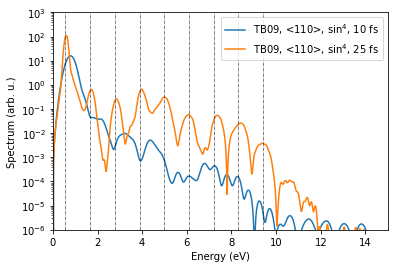

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [62]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2237e-9
plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(short_pulse_110[:,0], short_pulse_110[:,1], "-", label=r"TB09, <110>, $\sin^{4}$, 10 fs")
plt.semilogy(long_pulse_110[:,0],  long_pulse_110[:,1], "-",  label=r"TB09, <110>, $\sin^{4}$, 25 fs")
plt.xlim([0,15])
plt.ylim([1E-6,1E3])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-TB09-110-SinFourth-10fsVS25fs-"+str(round(float(Efield)/1E9,1))+"Vnm-Decoherence"+decoherence+"tau.eps")
plt.show()
%pwd

Effect of pulse duration is then major on the HHG spectrum. Would we need a longer pulse to reveal symmetries in better way? 

## Effect of orientation (sin4, LDA, 15 fs)

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


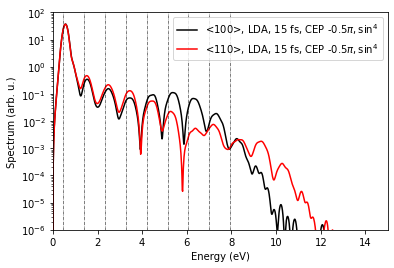

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [63]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2656e-9
CEP="-0.5"
decoherence="1.5"
# from scipy.constants import h, c, hbar, e
path0="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau1.9921875e-14-field1.4E9-CEP"+CEP+"-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path45="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau1.9921875e-14-field1.4E9-CEP"+CEP+"-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
spectrum0=np.loadtxt(path0, delimiter="\t")
spectrum45=np.loadtxt(path45, delimiter="\t")
plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(spectrum0[:,0], spectrum0[:,1],   "k-", label=r"<100>, LDA, 15 fs, CEP "+CEP+"$\pi, \sin^4$")
plt.semilogy(spectrum45[:,0], spectrum45[:,1], "r-", label=r"<110>, LDA, 15 fs, CEP "+CEP+"$\pi, \sin^4$")
plt.xlim([0,15])
plt.ylim([1E-6,1E2])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-LDA-100vs110-"+str(round(float(Efield)/1E9,1))+"Vnm-15fs-SinFourth-CEP"+CEP+"Decoherence"+decoherence+"tau.eps")
plt.show()
%pwd

## Effect of orientation (sin4, TB09)

### 10 fs

In [64]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2237e-9
decoherence="1.75"
path_short_pulse_100="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.75tau/HHG-Spectrum.csv"
path_short_pulse_110="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau11.1842e-15-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.75tau/HHG-Spectrum.csv"
spectrum0=np.loadtxt(path_short_pulse_100, delimiter="\t")
spectrum45=np.loadtxt(path_short_pulse_110, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


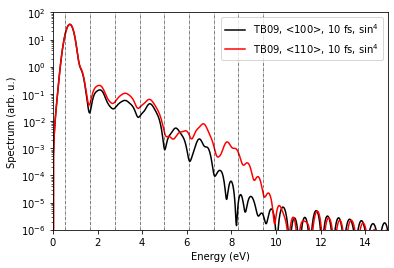

In [65]:
plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(spectrum0[:,0], spectrum0[:,1],   "k-", label=r"TB09, <100>, 10 fs, $\sin^{4}$")
plt.semilogy(spectrum45[:,0], spectrum45[:,1], "r-", label=r"TB09, <110>, 10 fs, $\sin^{4}$")
plt.xlim([0,15])
plt.ylim([1E-6,1E2])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-TB09-100vs110-10fs-SinFourth-"+str(float(wavelength*1E9))+"nm-"+str(float(Efield)/1E9)+"Vnm.eps")
plt.show()

### 25 fs

In [66]:
decoherence="1.75"

In [67]:
path_long_pulse_100="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_long_pulse_110="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
print(path_long_pulse_100)
print(path_long_pulse_110)

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.75tau/HHG-Spectrum.csv
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence1.75tau/HHG-Spectrum.csv


In [68]:
long_pulse_100=np.loadtxt(path_long_pulse_100, delimiter="\t")
long_pulse_110=np.loadtxt(path_long_pulse_110, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


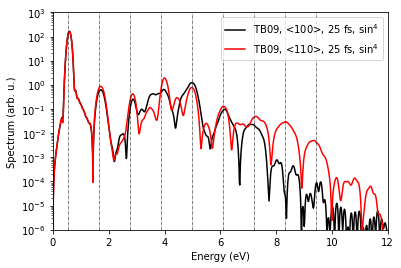

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [69]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2237e-9
plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(long_pulse_100[:,0], long_pulse_100[:,1], "k-", label=r"TB09, <100>, 25 fs, $\sin^{4}$")
plt.semilogy(long_pulse_110[:,0], long_pulse_110[:,1], "r-", label=r"TB09, <110>, 25 fs, $\sin^{4}$")
# plt.xlim([0,15])
plt.xlim([0,12])
plt.ylim([1E-6,1E3])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-TB09-100vs110-SinFourth-25fs-"+str(float(wavelength*1E9))+"nm-"+str(round(float(Efield)/1E9,1))+"Vnm-"+decoherence+"tau.eps")
plt.show()
%pwd

### Centering the CEP ?

In [70]:
decoherence="1.75"
path_long_pulse_110_random="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_long_pulse_110_centered="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP-0.45-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [71]:
long_pulse_110_rand=np.loadtxt(path_long_pulse_110_random, delimiter="\t")
long_pulse_110_center=np.loadtxt(path_long_pulse_110_centered, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


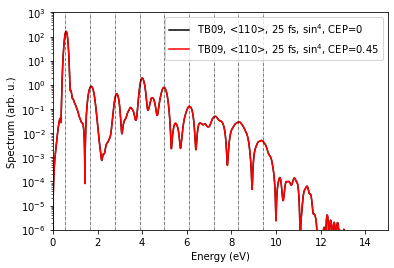

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [72]:
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2237e-9
plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(long_pulse_110_rand[:,0], long_pulse_110_rand[:,1], "k-", label=r"TB09, <110>, 25 fs, $\sin^{4}$, CEP=0")
plt.semilogy(long_pulse_110_center[:,0], long_pulse_110_center[:,1], "r-", label=r"TB09, <110>, 25 fs, $\sin^{4}$, CEP=0.45")
plt.xlim([0,15])
plt.ylim([1E-6,1E3])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-TB09-100vs110-SinFourth-25fs-"+str(round(float(Efield)/1E9,1))+"Vnm-CEPcentered-Decoherence"+decoherence+"tau.eps")
plt.show()
%pwd

### Changing wavelength to 750 nm, 6 fs

In [73]:
wavelength=8.388157894736841e-07 #750 nm normalized to TB09
tau=6.710526315789472e-15 #conservation of optical cycles for 6fs pulses induced by normalization
decoherence="1.75"

In [74]:
path_long_pulse_100="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda8.388157894736841e-07-tau6.710526315789472e-15-field2E9-CEP0.225-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_long_pulse_110="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda8.388157894736841e-07-tau6.710526315789472e-15-field2E9-CEP0.225-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [75]:
long_pulse_100=np.loadtxt(path_long_pulse_100, delimiter="\t")
long_pulse_110=np.loadtxt(path_long_pulse_110, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


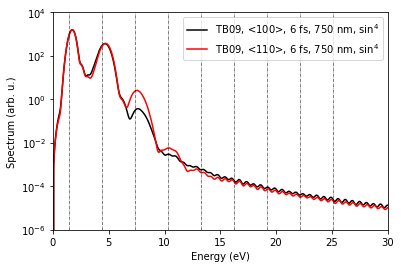

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [76]:
from scipy.constants import c, h, hbar, e

Efield="2E9" #1.4E9 3E9 9E9

plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(long_pulse_100[:,0], long_pulse_100[:,1], "k-", label=r"TB09, <100>, 6 fs, 750 nm, $\sin^{4}$")
plt.semilogy(long_pulse_110[:,0], long_pulse_110[:,1], "r-", label=r"TB09, <110>, 6 fs, 750 nm, $\sin^{4}$")
# plt.xlim([0,15])
plt.xlim([0,30])
plt.ylim([1E-6,1E4])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-TB09-100vs110-SinFourth-6fs-"+str(round(float(wavelength*1E9),1))+"nm-"+str(round(float(Efield)/1E9,1))+"Vnm-"+decoherence+"tau.eps")
plt.show()
%pwd

### Effect of decoherence time

In [77]:
decoherence="1.75" #1, 1.25, 1.5, 1.75, 2

In [78]:
# good data
path_long_pulse_100="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda8.388157894736841e-07-tau6.710526315789472e-15-field2E9-CEP0.225-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
path_long_pulse_110="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda8.388157894736841e-07-tau6.710526315789472e-15-field2E9-CEP0.225-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [79]:
# bad data
# path_long_pulse_100="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda8.388157894736841e-07-tau6.710526315789472e-15-field2E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"
# path_long_pulse_110="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda8.388157894736841e-07-tau6.710526315789472e-15-field2E9-CEP0.0-theta0.25-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/Decoherence"+decoherence+"tau/HHG-Spectrum.csv"

In [80]:
long_pulse_100=np.loadtxt(path_long_pulse_100, delimiter="\t")
long_pulse_110=np.loadtxt(path_long_pulse_110, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


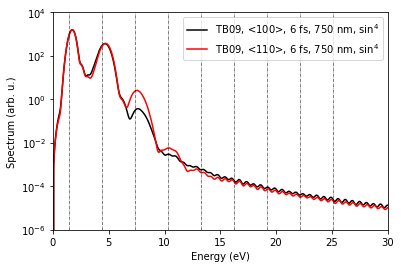

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [81]:
from scipy.constants import c, h, hbar, e

Efield="2E9" #1.4E9 3E9 9E9

plt.figure()
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.semilogy(long_pulse_100[:,0], long_pulse_100[:,1], "k-", label=r"TB09, <100>, 6 fs, 750 nm, $\sin^{4}$")
plt.semilogy(long_pulse_110[:,0], long_pulse_110[:,1], "r-", label=r"TB09, <110>, 6 fs, 750 nm, $\sin^{4}$")
# plt.xlim([0,15])
plt.xlim([0,30])
plt.ylim([1E-6,1E4])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-TB09-100vs110-SinFourth-6fs-"+str(round(float(wavelength*1E9),1))+"nm-"+str(round(float(Efield)/1E9,1))+"Vnm-"+decoherence+"tau.eps")
plt.show()
%pwd

# Effect of electron temperature

In [82]:
import numpy as np
# Te0eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP-0.45-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
Te0eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.0-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
Te0_025eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te0.025eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
Te0_05eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te0.05eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
Te0_1eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te0.1eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
Te0_5eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te0.5eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
Te1eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te1eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
TeIndirectGap="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te1.09eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
Te2eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te2eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
TeDirectGap="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te3.06eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
Te5eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te5eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
Te10eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te10eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
Te20eV="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-Te20eV-TB09/lambda2237e-9-tau2.7960526315789472e-14-field1.4E9-CEP0.25-theta0-SinFourth-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"

In [83]:
Te0eV_t=np.loadtxt(Te0eV, delimiter="\t")
Te0_025eV_t=np.loadtxt(Te0_025eV, delimiter="\t")
Te0_05eV_t=np.loadtxt(Te0_05eV, delimiter="\t")
Te0_1eV_t=np.loadtxt(Te0_1eV, delimiter="\t")
Te0_5eV_t=np.loadtxt(Te0_5eV, delimiter="\t")
Te1eV_t=np.loadtxt(Te1eV, delimiter="\t")
TeIndirectGap_t=np.loadtxt(TeIndirectGap, delimiter="\t")
Te2eV_t=np.loadtxt(Te2eV, delimiter="\t")
TeDirectGap_t=np.loadtxt(TeDirectGap, delimiter="\t")
Te5eV_t=np.loadtxt(Te5eV, delimiter="\t")
Te10eV_t=np.loadtxt(Te10eV, delimiter="\t")
Te20eV_t=np.loadtxt(Te20eV, delimiter="\t")

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


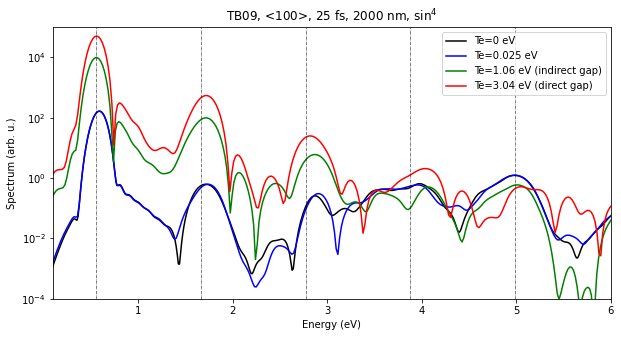

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [84]:
from scipy.constants import c, h, hbar, e
import matplotlib.pyplot as plt
decoherence="1.75"
Efield="1.4E9" #1.4E9 3E9 9E9
wavelength=2237e-9


plt.figure(figsize=(10,5))
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")
plt.title(r"TB09, <100>, 25 fs, 2000 nm, $\sin^{4}$")
plt.semilogy(Te0eV_t[:,0], Te0eV_t[:,1], "k-", label=r"Te=0 eV")
plt.semilogy(Te0_025eV_t[:,0], Te0_025eV_t[:,1], "b-", label=r"Te=0.025 eV")
# plt.semilogy(Te0_05eV_t[:,0], Te0_05eV_t[:,1], "b--", label=r"Te=0.05 eV")
# plt.semilogy(Te0_1eV_t[:,0], Te0_1eV_t[:,1], "g--", label=r"Te=0.1 eV")
# plt.semilogy(Te0_2eV_t[:,0], Te0_2eV_t[:,1], "-", label=r"Te=0.2 eV")
# plt.semilogy(Te0_5eV_t[:,0], Te0_5eV_t[:,1], "p--", label=r"Te=0.5 eV")
# plt.semilogy(Te1eV_t[:,0], Te1eV_t[:,1], "o--", label=r"Te=1 eV")
plt.semilogy(TeIndirectGap_t[:,0], TeIndirectGap_t[:,1], "g-", label=r"Te=1.06 eV (indirect gap)")
# plt.semilogy(Te2eV_t[:,0], Te2eV_t[:,1], "r--", label=r"Te=2 eV")
plt.semilogy(TeDirectGap_t[:,0], TeDirectGap_t[:,1], "r-", label=r"Te=3.04 eV (direct gap)")
# plt.xlim([0,15])
plt.xlim([0.1,6])
plt.ylim([1E-4,1E5])
for NumPhot in [1,3,5,7,9,11,13,15,17]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc="best")
plt.savefig("Si-k40-TB09-100-SinFourth-25fs-"+str(round(float(wavelength*1E9),1))+"nm-"+str(round(float(Efield)/1E9,1))+"Vnm-"+decoherence+"tau-EffectOfTe.eps")
plt.show()
%pwd

Idea Nov 12th 2022, 5:15pm
Maybe the evolution of the HHG is driven by the change of Fermi level? Let's plot Fermi level as function of electron temperature. 

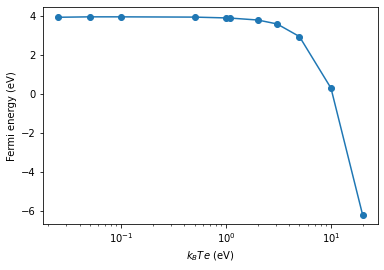

In [85]:
Te=[0.025,0.05, 0.10, 0.5, 1, 1.09, 2, 3.06, 5, 10, 20]
Fermi_Hartree=[0.143727, 0.144521, 0.144515, 0.144024, 0.142498, 0.142205, 0.138572, 0.131176, 0.107507, 0.010444, -0.227267]
import octopus_slabs.Libs.libAtomicUnits as lau
Fermi_eV=lau.Energy_Hartree_to_eV(Fermi_Hartree)
plt.figure()
plt.semilogx(Te, Fermi_eV, "o-")
plt.xlabel(r"$k_B Te$ (eV)")
plt.ylabel(r"Fermi energy (eV)")
plt.savefig("Si-TeDFT-TB09-TeOfFermiLevel.eps")
plt.show()

In [86]:
!pwd

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Bicolor pulses: effect of few percent second harmonic with $\omega+3\omega$

### Field = $1.4$ V/nm

Note that indicated CEP are CEP of the electric field, assuming that we have relation
$CEP_E = CEP_A + \pi/2$. This is true only for pulse with infinite envelope. 

In [105]:
# folder="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau33.55e-15-dt0.25-field1.4E9-CEP-0.375-theta0-SinFourth-SinPower2-2"
# folder="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau33.55e-15-dt0.25-field1.4E9-CEP0.21-theta0-SinFourth-SinPower2-2"
folder="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau33.55e-15-dt0.25-field1.6E9-CEP0.21-theta0-SinFourth-SinPower2-2"
CEPvals=np.round(np.linspace(-1.0, 0.9, 20),2)
# CEPvals=np.round([-0.5,-0.4,-0.3,-0.2,-0.1,0,0.1,0.2,0.4,0.5],1)
CEPvals=np.round(-1*CEPvals[::-1],1) #what a shameful bug (-0 *to 0)
print(CEPvals)
subfolder=[]
for CEP in CEPvals:
    #print(CEP)
    subfolder.append("/lambda745.61e-9-tau33.55e-15-field7E7-CEP"+str(CEP)+"-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv")


[-0.9 -0.8 -0.7 -0.6 -0.5 -0.4 -0.3 -0.2 -0.1  0.   0.1  0.2  0.3  0.4
  0.5  0.6  0.7  0.8  0.9  1. ]


In [106]:
HHGspectrum=[]
#print(len(CEPvals))
#print(np.arange(0,len(CEPvals)))
for index in np.arange(0,len(CEPvals)):
    #print(index)
    HHGspectrum.append(np.loadtxt(folder+subfolder[index], delimiter="\t"))

In [107]:
# Result without second pulse CEP1 -0.375
HHGspectrum0_path="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau33.55e-15-dt0.25-field1.4E9-CEP-0.375-theta0-SinFourth-SinPower2-2/lambda745.61e-9-tau33.55e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
HHGspectrum0=np.loadtxt(HHGspectrum0_path, delimiter="\t")

# Result without second pulse CEP1 0.21
HHGspectrum1_path="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau33.55e-15-dt0.25-field1.6E9-CEP0.21-theta0-SinFourth-SinPower2-2/lambda745.61e-9-tau33.55e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
# HHGspectrum1_path="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau33.55e-15-dt0.25-field1.4E9-CEP0.21-theta0-SinFourth-SinPower2-2/lambda745.61e-9-tau33.55e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv"
HHGspectrum1=np.loadtxt(HHGspectrum1_path, delimiter="\t")

OSError: /home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau33.55e-15-dt0.25-field1.6E9-CEP0.21-theta0-SinFourth-SinPower2-2/lambda745.61e-9-tau33.55e-15-field0E0-CEP0.0-delay0e-15-SinFourth/td.general/HHG-Spectrum.csv not found.

  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
  matplotlib.backends.backend_ps - _is_transparent - WARNING - The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


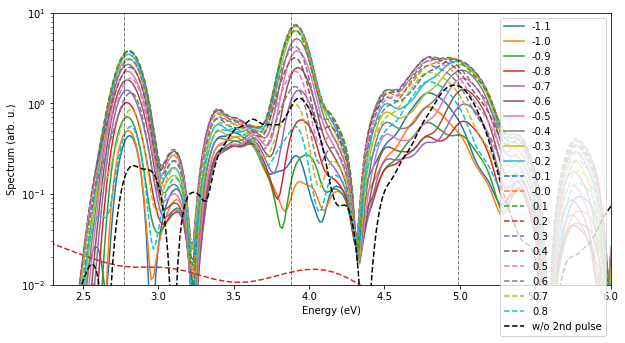

'/home/thibault.derrien/Documents/octopus.data/03-Bulk3D'

In [108]:
from scipy.constants import c, h, hbar, e, pi

# Efield="1.4E9" #1.4E9 3E9 9E9
Efield1="1.6E9"
CEP1=0.21 #-0.375
# CEP1=-0.375

plt.figure(figsize=(10,5))
plt.xlabel("Energy (eV)")
plt.ylabel("Spectrum (arb. u.)")

for index in np.arange(0,len(CEPvals)//2):
    plt.semilogy(HHGspectrum[index][:,0], HHGspectrum[index][:,1], "-", label=np.round(CEPvals[index]-CEP1,1))
    
for index in np.arange(len(CEPvals)//2,len(CEPvals)):
    plt.semilogy(HHGspectrum[index][:,0], HHGspectrum[index][:,1], "--", label=np.round(CEPvals[index]-CEP1,1))
                 #label=r"TB09, <100>, 30 fs, $\sin^{4}$")
        
# plt.semilogy(HHGspectrum0[:,0], HHGspectrum0[:,1], "-k", label="w/o 2nd pulse")
plt.semilogy(HHGspectrum1[:,0], HHGspectrum1[:,1], "--k", label="w/o 2nd pulse")
        
plt.xlim([2.3,6])
# plt.xlim([0,10])
plt.ylim([1E-2,1E1])
# plt.ylim([3E-1,5E0])
for NumPhot in [5,7,9]:
    plt.axvline(x=NumPhot*h*c/e/wavelength, color='k', linewidth=0.5, linestyle="-.")
plt.legend(loc=1)
plt.savefig("Si-k40-TB09-100-SinFourth-30fs-2000+666nm-"+str(round(float(Efield)/1E9,1))+"Vnm-CEP1"+str(round(CEP1,2))+"pi-RoleOfCEP2"+decoherence+"tau.eps")
plt.show()
%pwd
# HHGspectrum